In [20]:
using Distributions
using StatsPlots

"""
単回帰分析を実行し、回帰係数と誤差分散の不偏推定量を計算する関数
"""
function fit_linear_regression(x::Vector{Float64}, y::Vector{Float64})
    n = length(x)
    @assert n == length(y) "x と y のサイズが一致していません"
    @assert n > 2 "データ数は 3 以上必要です"

    # 平均の計算
    x_bar = mean(x)
    y_bar = mean(y)

    # 平方和 Sxx と 偏差積和 Sxy の計算
    Sxx = sum((xi - x_bar)^2 for xi in x)
    Sxy = sum((xi - x_bar) * (yi - y_bar) for (xi, yi) in zip(x, y))

    # 傾き (beta1) と 切片 (beta0) の推定
    betahat1 = Sxy / Sxx
    betahat0 = y_bar - betahat1 * x_bar
    
    # 回帰直線
    yhat(x) = evalpoly(x, (betahat0, betahat1))

    # 残差平方和 (SSE) と 誤差分散 (sigma^2) の不偏推定 (自由度: n - 2)
    sse = sum((yi - yhat(xi))^2 for (xi, yi) in zip(x, y))
    sigma2 = sse / (n - 2)
    sigma = sqrt(sigma2)

    return (; 
        betahat0,
        betahat1,
        yhat,
        sigma2,
        sigma,
        n,
        x_bar,
        Sxx,
    )
end

"""
任意の点 x0 における予測値、信頼区間（平均値の区間）、予測区間（個々の観測値の区間）を計算する関数
"""
function predict_intervals(model; alpha=0.05)
    (; n, sigma, yhat, x_bar, Sxx) = model
    
    # 自由度 n - 2 の t 分布の上側 alpha/2 点
    t_val = cquantile(TDist(n - 2), alpha / 2)

    # 信頼区間 (Confidence Interval) の計算
    se_fit(x) = sigma * sqrt(1/n + (x - x_bar)^2 / Sxx)
    ci_lower(x) = yhat(x) - t_val * se_fit(x)
    ci_upper(x) = yhat(x) + t_val * se_fit(x)

    # 予測区間 (Prediction Interval) の計算
    se_pred(x) = sigma * sqrt(1 + 1/n + (x - x_bar)^2 / Sxx)
    pi_lower(x) = yhat(x) - t_val * se_pred(x)
    pi_upper(x) = yhat(x) + t_val * se_pred(x)

    return (;
        yhat,
        ci = (; lower = ci_lower, upper = ci_upper),
        pi = (; lower = pi_lower, upper = pi_upper),
    )
end

predict_intervals (generic function with 3 methods)

In [36]:
"""
回帰係数 β1 の推測統計量 (標準誤差、t値、p値、信頼区間) を計算する関数
"""
function inference_beta1(model; beta1=0.0, alpha=0.05)
    (; n, sigma, Sxx, betahat1) = model
    
    # β1 の標準誤差 (Standard Error)
    se_beta1 = sigma / sqrt(Sxx)
    
    # t値 (帰無仮説 β1 = 0)
    t_stat = (betahat1 - beta1) / se_beta1
    
    # 自由度 n - 2 の t分布
    dist = TDist(n - 2)
    
    # p値 (両側検定)
    # ccdf(dist, x) は 1 - cdf(dist, x) と同じで、精度良く上側確率を計算します
    p_value = 2ccdf(dist, abs(t_stat))
    
    # 信頼区間
    t_val = cquantile(dist, alpha / 2)
    ci_lower = betahat1 - t_val * se_beta1
    ci_upper = betahat1 + t_val * se_beta1
    
    return (;
        betahat1,
        se_beta1,
        t_stat,
        p_value,
        ci_beta1 = (lower = ci_lower, upper = ci_upper)
    )
end

inference_beta1 (generic function with 1 method)

切片 β0: 0.48857740686338436
傾き β1: 0.16425609740273325
誤差分散の不偏推定値 σ²: 0.06220166183489083
仮説 beta1 = 0 のP値: 0.35944343026899306
beta1の95% 信頼区間: [-0.19618162282148097, 0.5246938176269474]


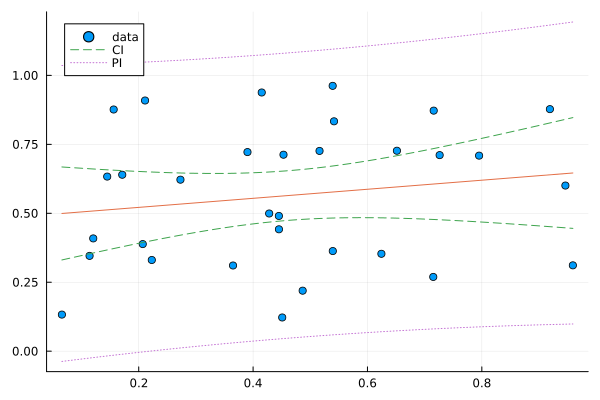

In [155]:
# サンプルデータ
#x = [1.0, 2.0, 3.0, 4.0, 5.0]
#y = [1.8, 3.2, 4.6, 5.5, 6.1]
n = 32
x = rand(n)
y = rand(n)

# 1. モデルの適合 (回帰係数と σ² の不偏推定)
model = fit_linear_regression(x, y)

println("切片 β0: ", model.betahat0)
println("傾き β1: ", model.betahat1)
println("誤差分散の不偏推定値 σ²: ", model.sigma2)

# 2. 95% 信頼区間・予測区間を計算する関数
alpha = 0.05
(; yhat, ci, pi) = predict_intervals(model; alpha)
(; se_beta1, t_stat, p_value, ci_beta1) = inference_beta1(model; alpha)

println("仮説 beta1 = 0 のP値: ", p_value)
println("beta1の95% 信頼区間: [", ci_beta1.lower, ", ", ci_beta1.upper, "]")

scatter(x, y; label="data")
plot!(yhat; label="", c=2)
plot!(ci.lower; label="CI", c=3, ls=:dash)
plot!(ci.upper; label="",   c=3, ls=:dash)
plot!(pi.lower; label="PI", c=4, ls=:dot)
plot!(pi.upper; label="",   c=4, ls=:dot)